In [71]:
"""
Pesäpallon lentoradan simulaatio 3D:ssä
========================================

Laajennus aiemmasta 2D-mallista. Fysiikka (ilmanvastus, Magnus-voima,
maahantörmäys) on sama, mutta nyt kaikki suureet ovat vektoreita
kolmessa ulottuvuudessa.

Koordinaatisto:
    x = päälyöntisuunta (vaakasuunta)
    y = pystysuunta (0 = maanpinta)
    z = sivuttaissuunta (vaakasuunta, kohtisuorassa x:ään nähden)

Lähtötiedot:
    - Nopeus: 3D-vektori (vx0, vy0, vz0)
    - Kierre: 2D-vektori (omega_y, omega_z)
        omega_z = "ylä-/alakierre" (topspin/backspin), pyörimisakseli
                  vaakasuuntainen z-akseli -> vaikuttaa pystysuuntaiseen
                  Magnus-nostoon/laskuun JA pallon pomppimiseen eteen-
                  taaksepäin (täsmälleen sama ilmiö kuin 2D-mallissa).
        omega_y = "sivukierre" (sidespin), pyörimisakseli pystysuuntainen
                  y-akseli -> vaikuttaa radan sivuttaiseen kaartumiseen
                  Magnus-voiman kautta, MUTTA ei suoraan pomppimiseen
                  (perustelu alla).
    - Tuuli: 2D-vektori (wind_x, wind_z), vaakatasossa - ei
      pystysuuntaista tuulikomponenttia.

Kolmas kierrekomponentti (omega_x, "kivääriä muistuttava" pyöriminen
suoraan lentosuunnan ympäri) EI ole osa lähtötietoja, koska se ei
sisälly 2D-kierrevektoriin. Sisäisesti pyörimisnopeus mallinnetaan
silti täytenä 3D-vektorina, koska maahan pompatessa kitka voi synnyttää
tämän kolmannen komponentin (ks. handle_bounce_3d) - tämä on aidosti
oikea fysikaalinen ilmiö (esim. sivuttain liukuva pallo alkaa pyöriä
liukumisen suunnan mukaan), ei approksimaatio.

HUOM epävarmuuksista: samat varaukset kuin 2D-mallissa - Cd(Re)-,
Cl(S)-, COR- ja kitka-arvot ovat baseball/softball-kirjallisuudesta
lainattuja ARVIOITA, ei pesäpallokohtaista mitattua dataa.
"""

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (tarvitaan 3D-projektioon)


# =====================================================================
#  VAKIOT JA PALLON OMINAISUUDET
# =====================================================================

# --- Pallon fysikaaliset ominaisuudet (lähde: Pesäpalloliiton säännöt) ---
BALL_MASS = 0.162           # kg, miesten pallo 160-165 g -> käytetään keskiarvoa
BALL_CIRCUMFERENCE = 0.219  # m, viralliset pallot 21.60-22.20 cm -> keskiarvo
BALL_RADIUS = BALL_CIRCUMFERENCE / (2 * np.pi)   # m
BALL_AREA = np.pi * BALL_RADIUS ** 2              # m^2, poikkileikkausala

# Hitausmomentin kerroin I = k * m * r^2. [ARVIO, ei julkista lähdettä]
INERTIA_FACTOR_K = 0.40

# --- Ilman ominaisuudet ---
AIR_DENSITY = 1.225       # kg/m^3
AIR_VISCOSITY = 1.8e-5    # Pa*s

# --- Painovoima ---
GRAVITY = 9.81            # m/s^2

# --- Ilmanvastuksen Cd(Re)-malli --- [ARVIO, baseball-kirjallisuudesta]
CD_HIGH = 0.50
CD_LOW = 0.30
CD_TRANSITION_RE = 1.5e5
CD_TRANSITION_WIDTH = 2.0e4

# --- Magnus-voiman kerroin --- [ARVIO, Nathanin baseball-malli]
MAGNUS_MODEL_MIN_SPEED = 0.5   # m/s, tätä hitaammalla Magnus nollataan

# --- Kierteen vaimeneminen ilmassa ---
SPIN_DECAY_TAU = 8.0       # s [ARVIO]

# --- Maahantörmäyksen parametrit --- [ARVIO, ei julkista Kihu-dataa]
RESTITUTION_COEFF = 0.45
FRICTION_COEFF = 0.70
MIN_BOUNCE_SPEED = 0.3
MAX_BOUNCES = 15

# --- Numeerisen integroinnin asetukset ---
DT = 0.001
MAX_SIM_TIME = 15.0


# =====================================================================
#  APUFUNKTIOT: ILMANVASTUS JA MAGNUS-VOIMA (3D)
# =====================================================================

def drag_coefficient(v_rel_mag):
    """Ilmanvastuskerroin Cd Reynoldsin luvun funktiona (sigmoidi-malli)."""
    if v_rel_mag < 1e-6:
        return CD_HIGH
    re = AIR_DENSITY * v_rel_mag * (2 * BALL_RADIUS) / AIR_VISCOSITY
    frac = 1.0 / (1.0 + np.exp((re - CD_TRANSITION_RE) / CD_TRANSITION_WIDTH))
    return CD_LOW + (CD_HIGH - CD_LOW) * frac


def lift_coefficient(spin_parameter):
    """Magnus-voiman kerroin Cl spin-parametrin S = r*|omega|/v funktiona."""
    s = abs(spin_parameter)
    if s < 1e-6:
        return 0.0
    return 1.0 / (2.0 + 1.0 / s)


def aerodynamic_forces_3d(v_vec, omega_vec, wind_vec_xz):
    """
    Laskee ilmanvastus- ja Magnus-voiman 3D-vektorina [N].

    v_vec        : pallon nopeusvektori (vx, vy, vz) [m/s]
    omega_vec    : pyörimisnopeusvektori (omega_x, omega_y, omega_z) [rad/s]
    wind_vec_xz  : tuulen nopeus (wind_x, wind_z) [m/s], vaakatasossa
    """
    wind_full = np.array([wind_vec_xz[0], 0.0, wind_vec_xz[1]])
    v_rel = v_vec - wind_full
    v_rel_mag = np.linalg.norm(v_rel)

    if v_rel_mag < 1e-6:
        return np.zeros(3)

    # --- Ilmanvastus: vastakkaissuuntainen suhteelliselle nopeudelle ---
    cd = drag_coefficient(v_rel_mag)
    f_drag = -0.5 * AIR_DENSITY * cd * BALL_AREA * v_rel_mag * v_rel

    # --- Magnus-voima: suunta (omega x v_rel), magnitudi Cl(S):n kautta ---
    if v_rel_mag < MAGNUS_MODEL_MIN_SPEED:
        f_magnus = np.zeros(3)
    else:
        omega_mag = np.linalg.norm(omega_vec)
        if omega_mag < 1e-9:
            f_magnus = np.zeros(3)
        else:
            cross = np.cross(omega_vec, v_rel)
            cross_mag = np.linalg.norm(cross)
            if cross_mag < 1e-9:
                # omega ja v_rel (lähes) yhdensuuntaiset -> ei Magnus-voimaa
                f_magnus = np.zeros(3)
            else:
                spin_param = BALL_RADIUS * omega_mag / v_rel_mag
                cl = lift_coefficient(spin_param)
                magnitude = 0.5 * AIR_DENSITY * cl * BALL_AREA * v_rel_mag ** 2
                f_magnus = magnitude * (cross / cross_mag)

    return f_drag + f_magnus


def spin_decay_vec(omega_vec):
    """Kierteen hidastuminen ilmanvastuksesta (sama aikavakio kaikille akseleille)."""
    return -omega_vec / SPIN_DECAY_TAU


# =====================================================================
#  LIIKEYHTÄLÖT JA RK4-INTEGROINTI (3D)
# =====================================================================

def derivatives_3d(state, wind_vec_xz):
    """
    state = [x, y, z, vx, vy, vz, omega_x, omega_y, omega_z]
    """
    pos = state[0:3]
    v_vec = state[3:6]
    omega_vec = state[6:9]

    force = aerodynamic_forces_3d(v_vec, omega_vec, wind_vec_xz)
    accel = force / BALL_MASS
    accel[1] -= GRAVITY  # painovoima y-suuntaan

    domega = spin_decay_vec(omega_vec)

    return np.concatenate([v_vec, accel, domega])


def rk4_step_3d(state, dt, wind_vec_xz):
    k1 = derivatives_3d(state, wind_vec_xz)
    k2 = derivatives_3d(state + 0.5 * dt * k1, wind_vec_xz)
    k3 = derivatives_3d(state + 0.5 * dt * k2, wind_vec_xz)
    k4 = derivatives_3d(state + dt * k3, wind_vec_xz)
    return state + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)


# =====================================================================
#  MAAHANTÖRMÄYKSEN MALLI (3D)
# =====================================================================
#
# Perustelu rakenteelle: pallon kontaktipiste maahan on suoraan pallon
# keskipisteen alapuolella, r_contact = (0, -R, 0). Kun lasketaan
# kitkaimpulssin aiheuttama vääntömomentti (r_contact x J_tangentti),
# osoittautuu että:
#   - vaakasuunta x ja pyöriminen omega_z KYTKEYTYVÄT toisiinsa
#     (täsmälleen sama fysiikka kuin alkuperäisessä 2D-mallissa)
#   - vaakasuunta z ja pyöriminen omega_x KYTKEYTYVÄT toisiinsa
#     (analoginen pari, sivuttaissuunnassa)
#   - pystyakselin pyöriminen omega_y EI kytkeydy kumpaankaan, koska
#     kontaktipiste sijaitsee juuri omega_y:n pyörimisakselilla ->
#     sillä ei ole liikettä tuon pyörimisen takia (vrt. hyrrä, joka
#     pyörii pystyakselinsa varassa: akselin alin piste ei liiku
#     pyörimisen takia, vaikka koko kappale pyöriikin).
#
# Näin (x, omega_z) ja (z, omega_x) voidaan käsitellä kahtena
# RIIPPUMATTOMANA parina täsmälleen samalla "liuku-vai-tartu"-logiikalla
# kuin 2D-mallissa, ja omega_y kulkee pomahduksen läpi muuttumattomana.


def _bounce_tangential_pair(v_lin, omega_rot, impulse_y_abs):
    """
    Ratkaisee yhden vaakasuunnan (x TAI z) ja siihen kytkeytyvän
    kierrekomponentin (omega_z TAI omega_x) uudet arvot pomppimisen
    jälkeen. Sama "liuku-vai-tartu"-malli kuin 2D-simulaatiossa.
    """
    slip = v_lin + BALL_RADIUS * omega_rot

    if abs(slip) < 1e-9:
        return v_lin, omega_rot

    friction_impulse = FRICTION_COEFF * impulse_y_abs

    # --- Oletus: pallo liukuu koko kontaktin ajan ---
    jt = -np.sign(slip) * friction_impulse
    v_new_slip = v_lin + jt / BALL_MASS
    omega_new_slip = omega_rot + jt * BALL_RADIUS / (
        INERTIA_FACTOR_K * BALL_MASS * BALL_RADIUS ** 2
    )
    slip_after = v_new_slip + BALL_RADIUS * omega_new_slip

    if np.sign(slip_after) != np.sign(slip):
        # --- Tarttumisratkaisu (rolling without slipping kontaktin lopussa) ---
        k = INERTIA_FACTOR_K
        v_new = (k * v_lin - omega_rot * BALL_RADIUS) / (1 + k)
        omega_new = -v_new / BALL_RADIUS
        return v_new, omega_new

    return v_new_slip, omega_new_slip


def handle_bounce_3d(vx, vy, vz, omega_x, omega_y, omega_z):
    """Laskee nopeus- ja kiervevektorit välittömästi maahantörmäyksen jälkeen."""
    if abs(vy) < 1e-6:
        return vx, vy, vz, omega_x, omega_y, omega_z

    # --- Normaalisuunta: kimmoisuuskerroin (sama kuin 2D-mallissa) ---
    vy_new = -RESTITUTION_COEFF * vy
    impulse_y_abs = BALL_MASS * abs(vy_new - vy)

    # --- Kaksi riippumatonta tangentiaalista paria ---
    vx_new, omega_z_new = _bounce_tangential_pair(vx, omega_z, impulse_y_abs)
    vz_new, omega_x_new = _bounce_tangential_pair(vz, omega_x, impulse_y_abs)

    # --- Pystyakselin kierre (sivukierre) säilyy pomppimisen yli ---
    omega_y_new = omega_y

    return vx_new, vy_new, vz_new, omega_x_new, omega_y_new, omega_z_new


# =====================================================================
#  KOKO SIMULAATIO: LENTO + POMPUT (3D)
# =====================================================================

def velocity_vector_from_angles(speed, launch_angle_deg, azimuth_deg):
    """
    Apufunktio: rakentaa 3D-nopeusvektorin nopeudesta, pystykulmasta
    (launch_angle, astetta vaakatasosta) ja vaakakulmasta (azimuth,
    astetta x-akselista z-akselia kohti). Ei pakollinen - nopeusvektorin voi antaa
    myös suoraan simulate_3d()-funktiolle.
    """
    angle = np.radians(launch_angle_deg)
    az = np.radians(azimuth_deg)
    vx = speed * np.cos(angle) * np.cos(az)
    vz = speed * np.cos(angle) * np.sin(az)
    vy = speed * np.sin(angle)
    return np.array([vx, vy, vz])


def simulate_3d(v0_vector, spin_vector_rpm, wind_vector, start_position=(0.0, 1.2, 0.0)):
    """
    Simuloi pallon radan lähtönopeudesta pysähtymiseen (tai aikarajaan).

    v0_vector        : lähtönopeus (vx0, vy0, vz0) [m/s]
    spin_vector_rpm  : kierre (omega_y, omega_z) [rpm]
                       omega_y = sivukierre (pystyakseli)
                       omega_z = ylä-/alakierre (vaaka-akseli, poikittain)
    wind_vector      : tuuli (wind_x, wind_z) [m/s], vaakatasossa
    start_height     : pallon lähtökorkeus [m]
    """
    omega_y0, omega_z0, omega_x0 = spin_vector_rpm
    omega_y0 = omega_y0 * 2 * np.pi / 60.0
    omega_z0 = omega_z0 * 2 * np.pi / 60.0
    omega_x0 = omega_x0 * 2 * np.pi / 60.0

    state = np.array([
        start_position[0], start_position[1], start_position[2],             # x, y, z
        v0_vector[0], v0_vector[1], v0_vector[2],  # vx, vy, vz
        omega_x0, omega_y0, omega_z0,            # omega_x, omega_y, omega_z
    ])

    t = 0.0
    trajectory = [state.copy()]
    times = [t]
    bounce_points = []
    n_bounces = 0

    while t < MAX_SIM_TIME:
        new_state = rk4_step_3d(state, DT, wind_vector)
        t += DT

        if new_state[1] <= 0.0 and state[1] > 0.0:
            # Interpoloidaan törmäyshetki tarkemmin
            frac = state[1] / (state[1] - new_state[1])
            touch = state + frac * (new_state - state)
            touch[1] = 0.0

            trajectory.append(touch.copy())
            times.append(t - DT + frac * DT)

            vx_n, vy_n, vz_n, ox_n, oy_n, oz_n = handle_bounce_3d(
                touch[3], touch[4], touch[5], touch[6], touch[7], touch[8]
            )
            bounce_points.append((touch[0], touch[2], n_bounces))
            n_bounces += 1

            state = np.array([
                touch[0], 1e-6, touch[2],
                vx_n, vy_n, vz_n,
                ox_n, oy_n, oz_n,
            ])
            trajectory.append(state.copy())
            times.append(times[-1])

            speed = np.linalg.norm([vx_n, vy_n, vz_n])
            if speed < MIN_BOUNCE_SPEED or n_bounces >= MAX_BOUNCES:
                break
            continue

        state = new_state
        trajectory.append(state.copy())
        times.append(t)

    trajectory = np.array(trajectory)
    return {
        "t": np.array(times),
        "x": trajectory[:, 0],
        "y": trajectory[:, 1],
        "z": trajectory[:, 2],
        "vx": trajectory[:, 3],
        "vy": trajectory[:, 4],
        "vz": trajectory[:, 5],
        "omega_x": trajectory[:, 6],
        "omega_y": trajectory[:, 7],
        "omega_z": trajectory[:, 8],
        "bounces": bounce_points,
    }


# =====================================================================
#  VISUALISOINTI
# =====================================================================

# Värit eri radoille (kierrätetään jos radoja on enemmän kuin värejä)
_TRAJECTORY_COLORS = [
    "tab:blue", "tab:orange", "tab:green", "tab:red",
    "tab:purple", "tab:brown", "tab:pink", "tab:gray",
]


def plot_result_3d(results, labels=None, title="Pesäpallon lentorata (3D)"):
    """
    Visualisoi yhden tai useamman radan samassa kuvassa.

    results : yksittäinen simulate_3d()-tuloksena saatu dict, TAI
              lista tällaisia dictejä (useamman radan vertailuun).
    labels  : lista nimiä radoille (näkyy legendassa). Jos None,
              käytetään automaattisesti "Rata 1", "Rata 2", jne.
              Ohitetaan, jos results on vain yksi rata.
    """
    # Sallitaan sekä yksittäinen rata että lista ratoja
    if isinstance(results, dict):
        results = [results]

    if labels is None:
        labels = [f"Rata {i + 1}" for i in range(len(results))]

    colors = [_TRAJECTORY_COLORS[i % len(_TRAJECTORY_COLORS)] for i in range(len(results))]

    fig = plt.figure(figsize=(13, 10))

    # --- 1) 3D-rata ---
    ax3d = fig.add_subplot(2, 2, 1, projection="3d")
    for result, label, color in zip(results, labels, colors):
        ax3d.plot(result["x"], result["z"], result["y"], color=color, linewidth=1.6, label=label)
        for (bx, bz, idx) in result["bounces"]:
            ax3d.scatter(bx, bz, 0, color=color, s=25, marker="o", edgecolor="black", linewidth=0.5)
    ax3d.set_xlabel("x [m]")
    ax3d.set_ylabel("z [m]")
    ax3d.set_zlabel("y [m]")
    ax3d.set_title("3D-rata")
    if len(results) > 1:
        ax3d.legend(loc="upper left", fontsize=8)

    # --- 2) Sivukuva (x-y) ---
    ax_side = fig.add_subplot(2, 2, 2)
    for result, label, color in zip(results, labels, colors):
        ax_side.plot(result["x"], result["y"], color=color, label=label)
        for (bx, bz, idx) in result["bounces"]:
            ax_side.plot(bx, 0, "o", color=color, markersize=5, markeredgecolor="black", markeredgewidth=0.5)
    ax_side.axhline(0, color="saddlebrown", linewidth=2)
    ax_side.set_xlabel("x [m]")
    ax_side.set_ylabel("y [m] (korkeus)")
    ax_side.set_title("Sivukuva (x-y)")
    ax_side.axis("equal")
    ax_side.grid(True, alpha=0.3)
    if len(results) > 1:
        ax_side.legend(loc="upper right", fontsize=8)

    # --- 3) Yläkuva (x-z) ---
    ax_top = fig.add_subplot(2, 2, 3)
    for result, label, color in zip(results, labels, colors):
        ax_top.plot(result["x"], result["z"], color=color, label=label)
        for (bx, bz, idx) in result["bounces"]:
            ax_top.plot(bx, bz, "o", color=color, markersize=5, markeredgecolor="black", markeredgewidth=0.5)
            ax_top.annotate(f"#{idx+1}", (bx, bz), textcoords="offset points",
                             xytext=(0, 6), ha="center", fontsize=7, color=color)
    ax_top.set_xlabel("x [m]")
    ax_top.set_ylabel("z [m] (sivuttaissuunta)")
    ax_top.set_title("Yläkuva (x-z) - kaartuminen näkyy tässä")
    ax_top.grid(True, alpha=0.3)
    ax_top.axis("equal")
    if len(results) > 1:
        ax_top.legend(loc="best", fontsize=8)

    # --- 4) Nopeus ajan funktiona (kierre jätetty pois moniratakuvasta selkeyden vuoksi) ---
    ax_v = fig.add_subplot(2, 2, 4)
    for result, label, color in zip(results, labels, colors):
        speed = np.linalg.norm(np.vstack([result["vx"], result["vy"], result["vz"]]), axis=0)
        speed = result["vy"]  # nopeus y-suuntaan (korkeus) ajan funktiona
        ax_v.plot(result["t"], speed, color=color, label=f"{label}: |v| [m/s]")
    ax_v.set_xlabel("Aika t [s]")
    ax_v.set_ylabel("Nopeus [m/s]")
    ax_v.grid(True, alpha=0.3)

    if len(results) == 1:
        # Yhden radan tapauksessa näytetään myös kierrenopeus omalla akselilla
        result = results[0]
        ax_o = ax_v.twinx()
        omega_mag = np.linalg.norm(
            np.vstack([result["omega_x"], result["omega_y"], result["omega_z"]]), axis=0
        )
        rpm = omega_mag * 60 / (2 * np.pi)
        ax_o.plot(result["t"], rpm, color="tab:purple", linestyle="--", label="|omega| [rpm]")
        ax_o.set_ylabel("Kierrenopeus [rpm]", color="tab:purple")
        ax_o.tick_params(axis="y", labelcolor="tab:purple")
        lines1, labels1 = ax_v.get_legend_handles_labels()
        lines2, labels2 = ax_o.get_legend_handles_labels()
        ax_v.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
    else:
        ax_v.legend(loc="upper right", fontsize=8)

    fig.suptitle(title)
    fig.tight_layout()
    return fig


Running simulation

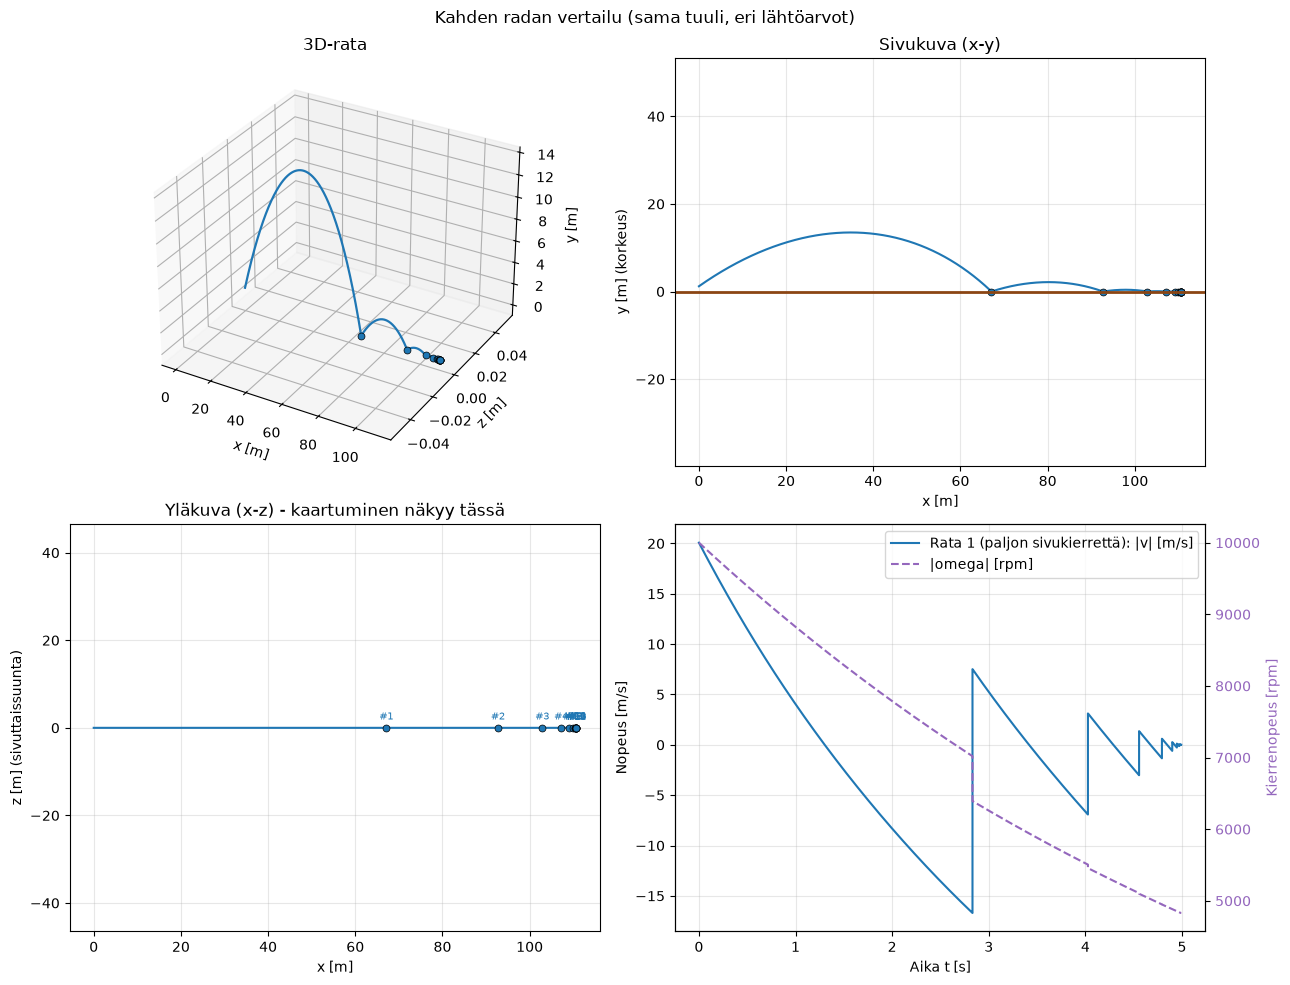

In [72]:
WIND_VECTOR = (0.0, 0.0)   # (wind_x, wind_z) m/s, sama tuuli molemmille

# --- Rata 1: enemmän sivukierrettä, pienempi ylä/alakierre ---
V0_1 = velocity_vector_from_angles(speed=35.0, launch_angle_deg=35.0, azimuth_deg=0.0)
result_1 = simulate_3d(
    v0_vector=V0_1,
    spin_vector_rpm=(0.0, -10000.0, 0.0),   # (omega_y, omega_z, omega_x) rpm
    wind_vector=WIND_VECTOR,
    start_position=(0.0, 1.2, 0.0)
)

fig = plot_result_3d(
    [result_1],
    labels=["Rata 1 (paljon sivukierrettä)"],
    title="Kahden radan vertailu (sama tuuli, eri lähtöarvot)",
)
fig.savefig("ball_trajectory_3d_comparison.png", dpi=150)

# Yhden radan visualisointi toimii edelleen ennallaan:
# fig_single = plot_result_3d(result_1, title="Yksittäinen rata")

plt.show()